# Decision Trees & Random Forests: Is Accuracy Enough?

**Questions**
1. How does a decision tree split the data, and what happens when it grows too deep?
2. Does a random forest really beat a single tree?
3. Is **accuracy** a good enough metric when classes are imbalanced?

**Data**
- **Kyphosis**: 81 children who had spinal surgery; did a spinal curvature (kyphosis) remain afterwards?
- **LendingClub loans**: 9,578 loans; was the loan **not fully paid** back?

**Tools:** pandas, seaborn, scikit-learn (`DecisionTreeClassifier`, `RandomForestClassifier`)

All splits and models use `random_state=101` so that the results can be reproduced.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set_style('whitegrid')

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, recall_score, f1_score)

---
# Part A: Kyphosis (small dataset)

In [2]:
kyph = pd.read_csv('data/kyphosis.csv')
kyph.head()

,Kyphosis,Age,Number,Start
0,absent,71,3,5
1,absent,158,3,14
2,present,128,4,5
3,absent,2,5,1
4,absent,1,4,15


In [3]:
kyph.info()

<class 'pandas.DataFrame'>
RangeIndex: 81 entries, 0 to 80
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Kyphosis  81 non-null     str  
 1   Age       81 non-null     int64
 2   Number    81 non-null     int64
 3   Start     81 non-null     int64
dtypes: int64(3), str(1)
memory usage: 3.2 KB


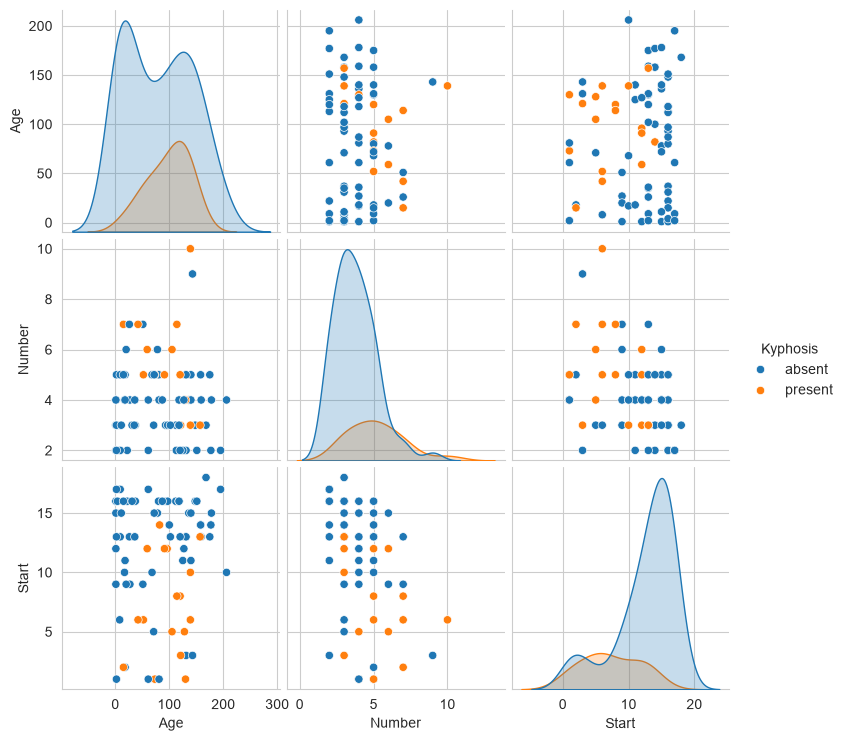

In [4]:
sns.pairplot(kyph, hue='Kyphosis')

In [5]:
X = kyph.drop('Kyphosis', axis=1)
y = kyph['Kyphosis']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

dtree = DecisionTreeClassifier(random_state=101).fit(X_train, y_train)
rfc = RandomForestClassifier(n_estimators=200, random_state=101).fit(X_train, y_train)

for name, model in [('Decision tree', dtree), ('Random forest (200 trees)', rfc)]:
    p = model.predict(X_test)
    print(name)
    print(confusion_matrix(y_test, p))
    print(classification_report(y_test, p))

Decision tree
[[12  5]
 [ 6  2]]
              precision    recall  f1-score   support

      absent       0.67      0.71      0.69        17
     present       0.29      0.25      0.27         8

    accuracy                           0.56        25
   macro avg       0.48      0.48      0.48        25
weighted avg       0.54      0.56      0.55        25

Random forest (200 trees)
[[17  0]
 [ 6  2]]
              precision    recall  f1-score   support

      absent       0.74      1.00      0.85        17
     present       1.00      0.25      0.40         8

    accuracy                           0.76        25
   macro avg       0.87      0.62      0.62        25
weighted avg       0.82      0.76      0.71        25



### A tree limited to depth 3 is easy to read

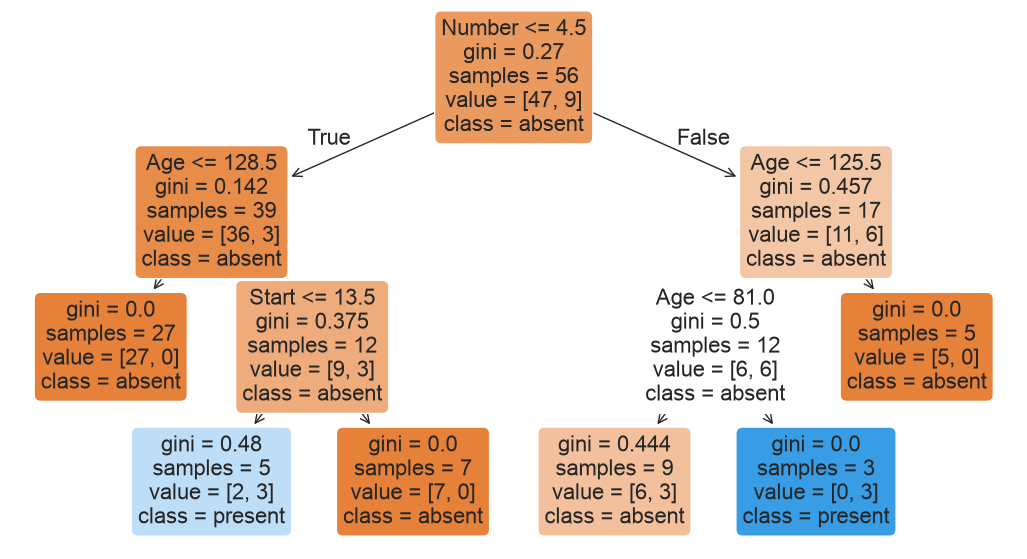

In [6]:
tree3 = DecisionTreeClassifier(max_depth=3, random_state=101).fit(X_train, y_train)

plt.figure(figsize=(13, 7))
plot_tree(tree3, feature_names=list(X.columns), class_names=['absent', 'present'], filled=True, rounded=True)
plt.show()

In [7]:
print('Unlimited tree -> depth:', dtree.get_depth(), 'leaves:', dtree.get_n_leaves())
print('   train acc:', round(dtree.score(X_train, y_train), 3), ' test acc:', round(dtree.score(X_test, y_test), 3))
print('Depth-3 tree   -> train acc:', round(tree3.score(X_train, y_train), 3), ' test acc:', round(tree3.score(X_test, y_test), 3))

Unlimited tree -> depth: 7 leaves: 12
   train acc: 1.0  test acc: 0.56
Depth-3 tree   -> train acc: 0.911  test acc: 0.72


The unlimited tree fits the training data perfectly (100%) but reaches only 56% on the test data, while the depth-3 tree reaches 72%: a clear sign of **overfitting**.

### How stable are these results?
With only 25 test children, one misclassified child changes accuracy by 4 percentage points. With a different random
split, the single tree can look *better* than the forest (in an earlier run: 84% vs. 76%); with this split it is the other way round.
5-fold cross-validation gives a more reliable comparison:

In [8]:
from sklearn.model_selection import cross_val_score

for name, model in [('Decision tree', DecisionTreeClassifier(random_state=101)),
                    ('Decision tree (max_depth=3)', DecisionTreeClassifier(max_depth=3, random_state=101)),
                    ('Random forest (200 trees)', RandomForestClassifier(n_estimators=200, random_state=101))]:
    scores = cross_val_score(model, X, y, cv=5)
    print(f'{name:28s} mean accuracy = {scores.mean():.3f}  (std {scores.std():.3f})')

Decision tree                mean accuracy = 0.778  (std 0.029)
Decision tree (max_depth=3)  mean accuracy = 0.778  (std 0.029)


Random forest (200 trees)    mean accuracy = 0.802  (std 0.062)


Cross-validation puts the random forest slightly ahead (≈80% vs. ≈78%), but the standard deviations are large
compared with the gap. On such a small dataset the ranking of models depends heavily on how the data is split, so the
differences should not be over-interpreted.

---
# Part B: LendingClub loans

In [9]:
loans = pd.read_csv('data/loan_data.csv')
loans.head()

,credit.policy,purpose,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
0,1,debt_consolidation,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0
1,1,credit_card,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0
2,1,debt_consolidation,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0
3,1,debt_consolidation,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0
4,1,credit_card,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0


In [10]:
loans.info()

<class 'pandas.DataFrame'>
RangeIndex: 9578 entries, 0 to 9577
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   credit.policy      9578 non-null   int64  
 1   purpose            9578 non-null   str    
 2   int.rate           9578 non-null   float64
 3   installment        9578 non-null   float64
 4   log.annual.inc     9578 non-null   float64
 5   dti                9578 non-null   float64
 6   fico               9578 non-null   int64  
 7   days.with.cr.line  9578 non-null   float64
 8   revol.bal          9578 non-null   int64  
 9   revol.util         9578 non-null   float64
 10  inq.last.6mths     9578 non-null   int64  
 11  delinq.2yrs        9578 non-null   int64  
 12  pub.rec            9578 non-null   int64  
 13  not.fully.paid     9578 non-null   int64  
dtypes: float64(6), int64(7), str(1)
memory usage: 1.2 MB


In [11]:
loans.describe()

,credit.policy,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
count,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000,9.578000e+03,9578.000000,9578.000000,9578.000000,9578.000000,9578.000000
mean,0.804970,0.122640,319.089413,10.932117,12.606679,710.846314,4560.767197,1.691396e+04,46.799236,1.577469,0.163708,0.062122,0.160054
std,0.396245,0.026847,207.071301,0.614813,6.883970,37.970537,2496.930377,3.375619e+04,29.014417,2.200245,0.546215,0.262126,0.366676
min,0.000000,0.060000,15.670000,7.547502,0.000000,612.000000,178.958333,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.103900,163.770000,10.558414,7.212500,682.000000,2820.000000,3.187000e+03,22.600000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,0.122100,268.950000,10.928884,12.665000,707.000000,4139.958333,8.596000e+03,46.300000,1.000000,0.000000,0.000000,0.000000
75%,1.000000,0.140700,432.762500,11.291293,17.950000,737.000000,5730.000000,1.824950e+04,70.900000,2.000000,0.000000,0.000000,0.000000
max,1.000000,0.216400,940.140000,14.528354,29.960000,827.000000,17639.958330,1.207359e+06,119.000000,33.000000,13.000000,5.000000,1.000000


## Exploratory analysis

Text(0.5, 0, 'FICO')

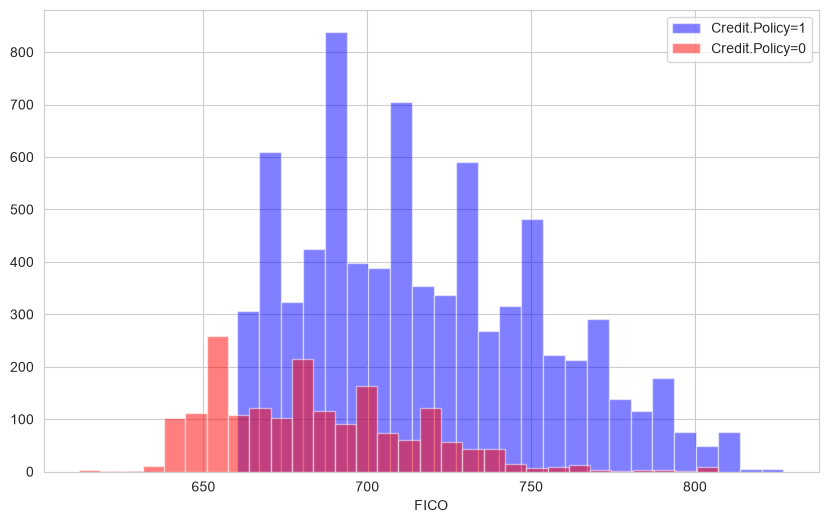

In [12]:
plt.figure(figsize=(10, 6))
loans[loans['credit.policy'] == 1]['fico'].hist(alpha=0.5, color='blue', bins=30, label='Credit.Policy=1')
loans[loans['credit.policy'] == 0]['fico'].hist(alpha=0.5, color='red', bins=30, label='Credit.Policy=0')
plt.legend()
plt.xlabel('FICO')

Text(0.5, 0, 'FICO')

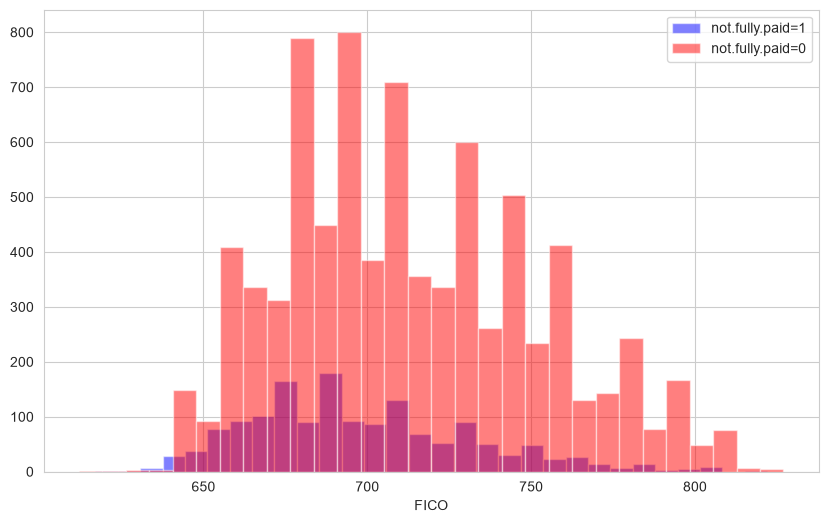

In [13]:
plt.figure(figsize=(10, 6))
loans[loans['not.fully.paid'] == 1]['fico'].hist(alpha=0.5, color='blue', bins=30, label='not.fully.paid=1')
loans[loans['not.fully.paid'] == 0]['fico'].hist(alpha=0.5, color='red', bins=30, label='not.fully.paid=0')
plt.legend()
plt.xlabel('FICO')

Borrowers with lower FICO scores default a bit more often, but the two distributions overlap heavily, so FICO alone cannot separate them.

([0, 1, 2, 3, 4, 5, 6],
 [Text(0, 0, 'debt_consolidation'),
  Text(1, 0, 'credit_card'),
  Text(2, 0, 'all_other'),
  Text(3, 0, 'home_improvement'),
  Text(4, 0, 'small_business'),
  Text(5, 0, 'major_purchase'),
  Text(6, 0, 'educational')])

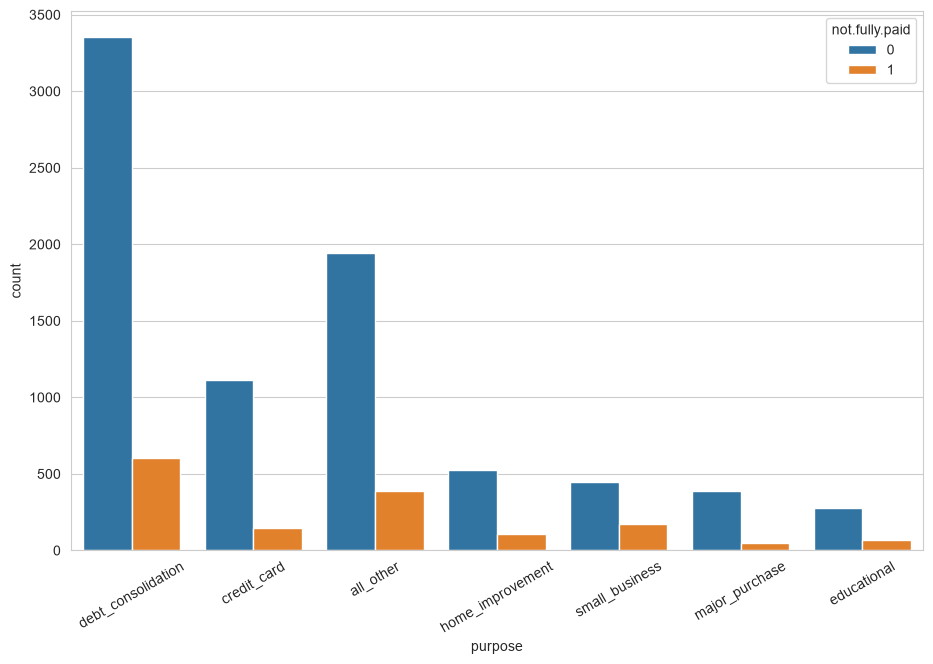

In [14]:
plt.figure(figsize=(11, 7))
sns.countplot(data=loans, x='purpose', hue='not.fully.paid')
plt.xticks(rotation=30)

In [15]:
(loans.groupby('purpose')['not.fully.paid'].mean()
      .sort_values(ascending=False).round(3).rename('default rate'))

purpose
small_business        0.278
educational           0.201
home_improvement      0.170
all_other             0.166
debt_consolidation    0.152
credit_card           0.116
major_purchase        0.112
Name: default rate, dtype: float64

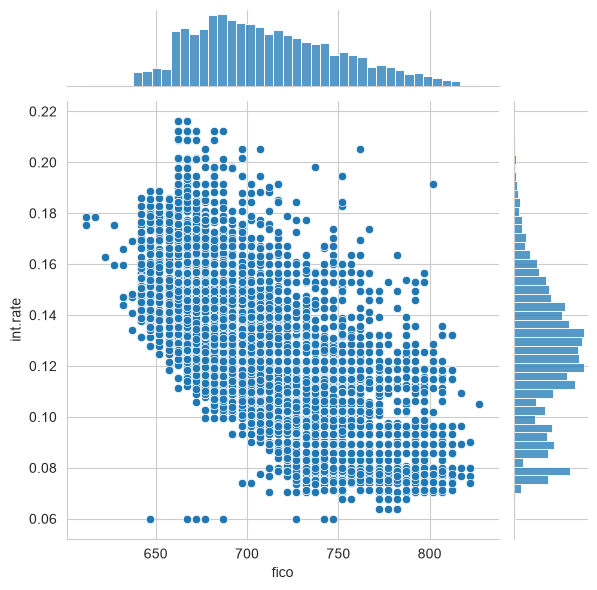

In [16]:
sns.jointplot(data=loans, x='fico', y='int.rate')

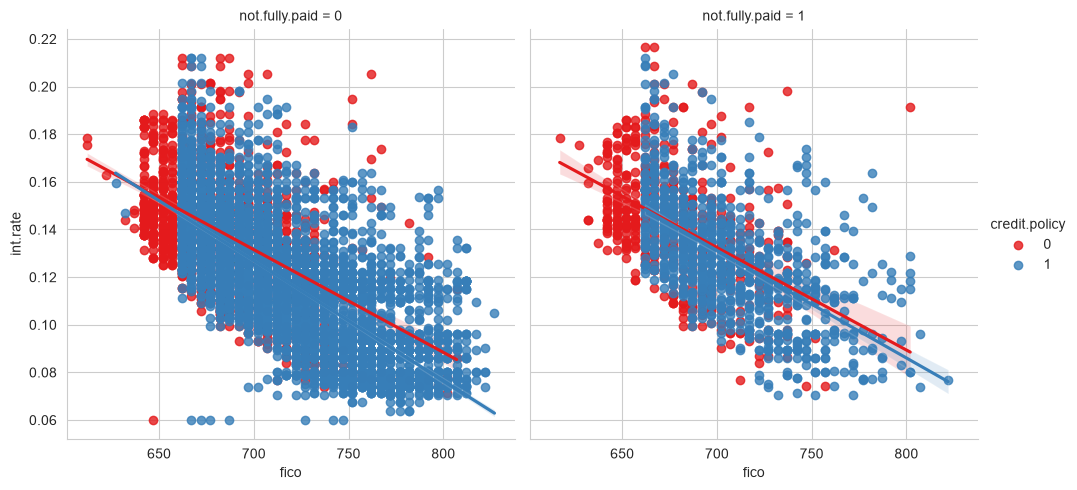

In [17]:
sns.lmplot(y='int.rate', x='fico', data=loans, hue='credit.policy',
           col='not.fully.paid', palette='Set1')

In [18]:
print('Share of each class:')
print(loans['not.fully.paid'].value_counts(normalize=True).round(3))

Share of each class:
not.fully.paid
0    0.84
1    0.16
Name: proportion, dtype: float64


About **84%** of loans were fully paid, so the data is **imbalanced**. A model that simply predicts "paid" for everyone would already be ~84% accurate.

## Preprocessing
`purpose` is categorical, so it is converted to dummy variables (`drop_first=True` avoids the dummy-variable trap).

In [19]:
final_data = pd.get_dummies(loans, columns=['purpose'], drop_first=True)

X = final_data.drop('not.fully.paid', axis=1)
y = final_data['not.fully.paid']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

print('Accuracy of always predicting 0 (paid):', round((y_test == 0).mean(), 3))

Accuracy of always predicting 0 (paid): 0.846


## Decision tree vs. random forest (default settings)

In [20]:
dtree = DecisionTreeClassifier(random_state=101).fit(X_train, y_train)
predictions = dtree.predict(X_test)
print(confusion_matrix(y_test, predictions))
print(classification_report(y_test, predictions))

[[2008  423]
 [ 341  102]]
              precision    recall  f1-score   support

           0       0.85      0.83      0.84      2431
           1       0.19      0.23      0.21       443

    accuracy                           0.73      2874
   macro avg       0.52      0.53      0.53      2874
weighted avg       0.75      0.73      0.74      2874



In [21]:
rfc = RandomForestClassifier(random_state=101).fit(X_train, y_train)
predictions = rfc.predict(X_test)
print(confusion_matrix(y_test, predictions))
print(classification_report(y_test, predictions))

[[2419   12]
 [ 433   10]]
              precision    recall  f1-score   support

           0       0.85      1.00      0.92      2431
           1       0.45      0.02      0.04       443

    accuracy                           0.85      2874
   macro avg       0.65      0.51      0.48      2874
weighted avg       0.79      0.85      0.78      2874



The random forest has much higher **accuracy**, but look at the recall for class 1: it catches almost none of the loans that were not repaid.
It wins on accuracy mostly by predicting "paid" for nearly everyone.

## Tree depth and overfitting

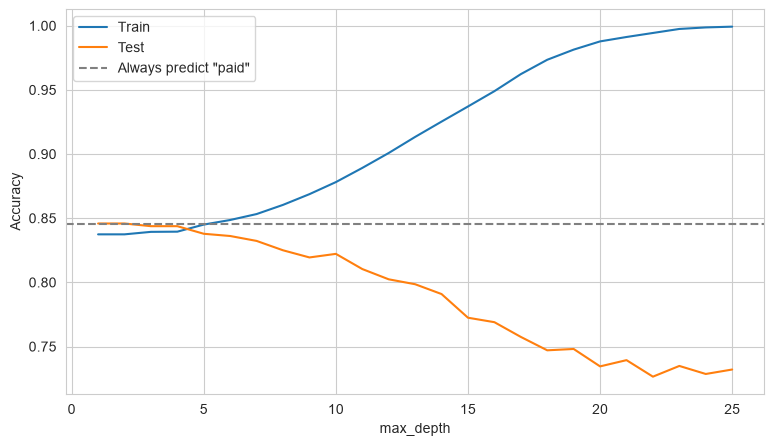

In [22]:
train_acc, test_acc = [], []
for d in range(1, 26):
    m = DecisionTreeClassifier(max_depth=d, random_state=101).fit(X_train, y_train)
    train_acc.append(m.score(X_train, y_train))
    test_acc.append(m.score(X_test, y_test))

plt.figure(figsize=(9, 5))
plt.plot(range(1, 26), train_acc, label='Train')
plt.plot(range(1, 26), test_acc, label='Test')
plt.axhline((y_test == 0).mean(), ls='--', color='gray', label='Always predict "paid"')
plt.xlabel('max_depth'); plt.ylabel('Accuracy'); plt.legend()
plt.show()

## Feature importance (random forest)

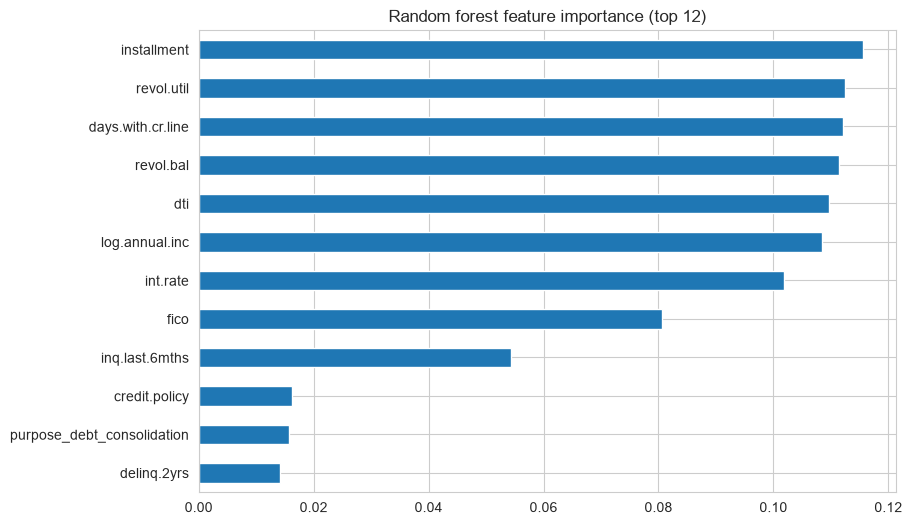

In [23]:
importance = pd.Series(rfc.feature_importances_, index=X.columns).sort_values()
importance.tail(12).plot(kind='barh', figsize=(9, 6))
plt.title('Random forest feature importance (top 12)')
plt.show()

## Taking class imbalance into account

In [24]:
models = {
    'DT default': DecisionTreeClassifier(random_state=101),
    'DT max_depth=5': DecisionTreeClassifier(max_depth=5, random_state=101),
    'DT max_depth=5 balanced': DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=101),
    'RF default': RandomForestClassifier(random_state=101),
    'RF balanced': RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample',
                                          min_samples_leaf=20, random_state=101),
}
rows = []
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    rows.append([name, accuracy_score(y_test, p), recall_score(y_test, p), f1_score(y_test, p)])

results = pd.DataFrame(rows, columns=['Model', 'Accuracy', 'Recall (class 1)', 'F1 (class 1)']).round(3)
results

,Model,Accuracy,Recall (class 1),F1 (class 1)
0,DT default,0.734,0.230,0.211
1,DT max_depth=5,0.838,0.027,0.049
2,DT max_depth=5 balanced,0.698,0.393,0.286
3,RF default,0.845,0.023,0.043
4,RF balanced,0.725,0.397,0.308


## Conclusion

| Model | Accuracy | Recall (not repaid) |
|---|---|---|
| Always predict "paid" | 0.846 | 0.00 |
| Decision tree | 0.734 | 0.23 |
| Random forest | 0.845 | **0.02** |
| Random forest, balanced | 0.725 | **0.40** |

1. **Accuracy is misleading on imbalanced data.** The default random forest looks best by accuracy, yet it catches
   only about 2% of the loans that were not repaid, which is no better than always predicting "paid".
2. **Class weighting changes the picture.** With `class_weight='balanced_subsample'` the forest catches about 40% of
   the bad loans. Accuracy drops, but for a lender missing a bad loan is usually far more costly than a false alarm.
3. **Deep trees overfit.** Training accuracy approaches 100% as depth grows, while test accuracy falls.
4. **Feature importance is spread out.** The continuous financial variables (`installment`, `revol.util`,
   `days.with.cr.line`, `revol.bal`, `dti`, `log.annual.inc`, `int.rate`) each have an importance of about 0.10-0.12,
   followed by `fico` (0.08), while the loan-purpose dummies matter little. (Impurity-based importance tends to favour
   continuous variables, so permutation importance would be a useful check.)

**Possible next steps:** a logistic regression baseline, ROC-AUC and precision-recall curves, tuning the decision
threshold, and cross-validated hyper-parameter search.